## This notebook will be used to work on the dataset "dirty_cafe_sales.csv" ##


In [52]:
# First we need to import pandas to work with DataFrames
import pandas as pd 
# Then read the .csv file into a dataframe 

df = pd.read_csv("./dirty_cafe_sales.csv")

# We should make all headers lowercase and without space
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')
df.columns


Index(['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent',
       'payment_method', 'location', 'transaction_date'],
      dtype='str')

In [53]:
# Let's check this DataFrame
# First 5 rows
df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [54]:
# Checking the information in the DataFrame
df.info()
# We can see we have 10000 rows in total
# However, all columns, except for Transaction ID, have missing values
# All columns are also described as str, not int or float

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   transaction_id    10000 non-null  str  
 1   item              9667 non-null   str  
 2   quantity          9862 non-null   str  
 3   price_per_unit    9821 non-null   str  
 4   total_spent       9827 non-null   str  
 5   payment_method    7421 non-null   str  
 6   location          6735 non-null   str  
 7   transaction_date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [55]:
# Checking basic descriptive statistics
df.describe()
# Because all values are stored as str, the descriptive statistics shown are for text values, not numbers
# UNKNOWN is also the most shown values for Transaction Date

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [56]:
# We need to convert 'quantity' from str to int,
# 'price_per_unit' and 'total_spent' from str to float and 'transaction_date' from str to datetime
print(df["quantity"].value_counts(dropna=False))   # before: shows the text values
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce").astype("Int64") # This converts all errors to NaN (values that are not numerical)
print(df["quantity"].isna().sum(), "missing after conversion")

quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64
479 missing after conversion


In [57]:
# Now the same with the other columns
for i in ['price_per_unit','total_spent']:
    print(df[i].value_counts(dropna=False))   # before: shows the text values
    df[i] = pd.to_numeric(df[i], errors="coerce").astype("float64") # This converts all errors to NaN (values that are not numerical)
    print(df[i].isna().sum(), "missing after conversion")
#df['transaction_date'] = 

price_per_unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164
Name: count, dtype: int64
533 missing after conversion
total_spent
6.0        979
12.0       939
3.0        930
4.0        923
20.0       746
15.0       734
8.0        677
10.0       524
2.0        497
9.0        479
5.0        468
16.0       444
25.0       259
7.5        237
1.0        232
4.5        225
1.5        205
NaN        173
UNKNOWN    165
ERROR      164
Name: count, dtype: int64
502 missing after conversion


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    10000 non-null  str    
 1   item              9667 non-null   str    
 2   quantity          9521 non-null   Int64  
 3   price_per_unit    9467 non-null   float64
 4   total_spent       9498 non-null   float64
 5   payment_method    7421 non-null   str    
 6   location          6735 non-null   str    
 7   transaction_date  9841 non-null   str    
dtypes: Int64(1), float64(2), str(5)
memory usage: 634.9 KB


In [59]:
print(df["transaction_date"].value_counts(dropna=False))   # before: shows the text values
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce") # This converts all errors to NaN (values that are not numerical)
print(df["transaction_date"].isna().sum(), "missing after conversion")

transaction_date
NaN           159
UNKNOWN       159
ERROR         142
2023-02-06     40
2023-06-16     40
             ... 
2023-09-24     15
2023-07-30     15
2023-03-11     14
2023-07-22     14
2023-02-17     14
Name: count, Length: 368, dtype: int64
460 missing after conversion


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  str           
 1   item              9667 non-null   str           
 2   quantity          9521 non-null   Int64         
 3   price_per_unit    9467 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    7421 non-null   str           
 6   location          6735 non-null   str           
 7   transaction_date  9540 non-null   datetime64[us]
dtypes: Int64(1), datetime64[us](1), float64(2), str(4)
memory usage: 634.9 KB


In [ ]:
# Now cleaning the missing data from the str columns
# Import numpy to work with nan
import numpy as np
str_cols = ['transaction_id', 'item', 'payment_method', 'location']
df[str_cols] = df[str_cols].replace(['UNKNOWN','ERROR'], np.nan)
df.isna().sum() # location and payment method had the most empty values

transaction_id         0
item                 969
quantity             479
price_per_unit       533
total_spent          502
payment_method      3178
location            3961
transaction_date     460
dtype: int64

In [70]:
df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [81]:
# Quantity, price per unit and total spent can be calculated
for i in df.index:
    q = df.loc[i, "quantity"]
    p = df.loc[i, "price_per_unit"]
    t = df.loc[i, "total_spent"]

    if pd.isna(q):
        df.loc[i, "quantity"] = t / p
    elif pd.isna(p):
        df.loc[i, "price_per_unit"] = t / q
    elif pd.isna(t):
        df.loc[i, "total_spent"] = q * p
df.describe()


,quantity,price_per_unit,total_spent,transaction_date
count,9962.0,9962.000000,9960.000000,9540
mean,3.025597,2.947902,8.930924,2023-07-01 23:00:31.698113
min,1.0,1.000000,1.000000,2023-01-01 00:00:00
25%,2.0,2.000000,4.000000,2023-04-01 00:00:00
50%,3.0,3.000000,8.000000,2023-07-02 00:00:00
75%,4.0,4.000000,12.000000,2023-10-02 00:00:00
max,5.0,5.000000,25.000000,2023-12-31 00:00:00
std,1.420181,1.279759,6.004475,NaN


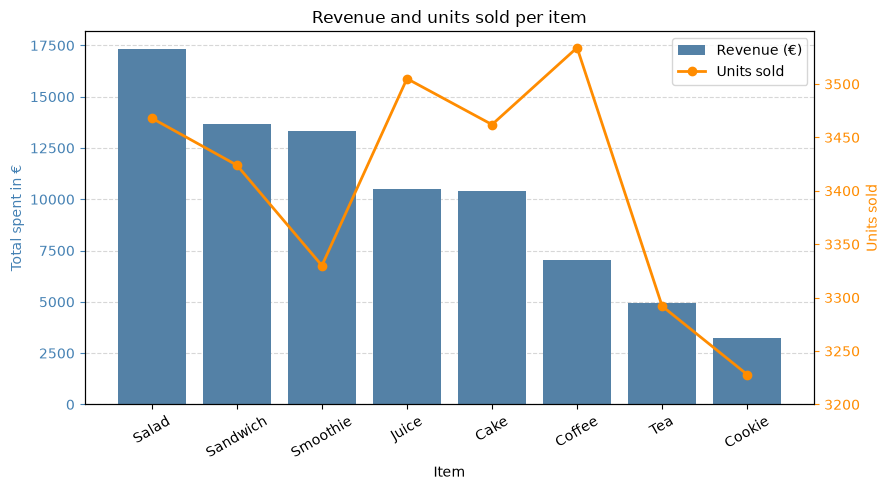

In [107]:
# Import seaborn to plot the data
import seaborn as sns
import matplotlib.pyplot as plt
# Totals per item, both in the same order
summary = (
    df.groupby("item")
      .agg(revenue=("total_spent", "sum"), units=("quantity", "sum"))
      .sort_values("revenue", ascending=False)
)
fig, ax = plt.subplots(figsize=(9, 5))

# Left axis: revenue as bars
sns.barplot(x=summary.index, y=summary["revenue"],
            color="steelblue", ax=ax, label="Revenue (€)")
ax.set_xlabel("Item")
ax.set_ylabel("Total spent in €", color="steelblue")
ax.tick_params(axis="y", colors="steelblue")
ax.tick_params(axis="x", rotation=30)
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)   # draw the grid behind the bars

# Right axis: units sold as a line with markers
ax2 = ax.twinx()
ax2.plot(range(len(summary)), summary["units"].astype(float),
         color="darkorange", marker="o", linewidth=2, label="Units sold")
ax2.set_ylabel("Units sold", color="darkorange")
ax2.tick_params(axis="y", colors="darkorange")
ax2.set_ylim(bottom=3200)

# One legend for both axes
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")

ax.set_title("Revenue and units sold per item")
plt.tight_layout()
plt.savefig('Revenue and units sold per item.jpeg')
plt.show()